In [24]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

load_dotenv(find_dotenv(usecwd=True))
url = URL.create("postgresql+psycopg2",
    username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
    host="localhost", port=5433, database="airline")
engine = create_engine(url)

df = pd.read_sql("SELECT * FROM train", engine)
print(df.shape)
df['arrival_delay'] = df['arrival_delay'].fillna(df['arrival_delay'].median())
df["satisfied"] = (df["satisfaction"] == "satisfied").astype(int)
df = df.drop(columns=['satisfaction'])


(103904, 25)
idx                        0
id                         0
gender                     0
customer_type              0
age                        0
type_of_travel             0
travel_class               0
flight_distance            0
inflight_wifi              0
dep_arr_time_convenient    0
online_booking             0
gate_location              0
food_and_drink             0
online_boarding            0
seat_comfort               0
inflight_entertainment     0
onboard_service            0
leg_room                   0
baggage_handling           0
checkin_service            0
inflight_service           0
cleanliness                0
departure_delay            0
arrival_delay              0
satisfaction               0
dtype: int64


In [25]:
print(df.describe())

                 idx             id            age  flight_distance  \
count  103904.000000  103904.000000  103904.000000    103904.000000   
mean    51951.500000   64924.210502      39.379706      1189.448375   
std     29994.645522   37463.812252      15.114964       997.147281   
min         0.000000       1.000000       7.000000        31.000000   
25%     25975.750000   32533.750000      27.000000       414.000000   
50%     51951.500000   64856.500000      40.000000       843.000000   
75%     77927.250000   97368.250000      51.000000      1743.000000   
max    103903.000000  129880.000000      85.000000      4983.000000   

       inflight_wifi  dep_arr_time_convenient  online_booking  gate_location  \
count  103904.000000            103904.000000   103904.000000  103904.000000   
mean        2.729683                 3.060296        2.756901       2.976883   
std         1.327829                 1.525075        1.398929       1.277621   
min         0.000000                 0.0

<Axes: xlabel='dep_arr_time_convenient', ylabel='Count'>

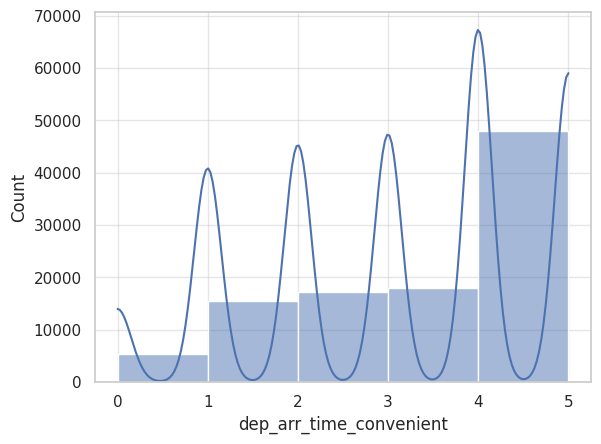

In [26]:
sns.histplot(data=df, x='dep_arr_time_convenient', bins=5, kde=True)

/tmp/ipykernel_257662/589381040.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='online_booking', palette='Set2')


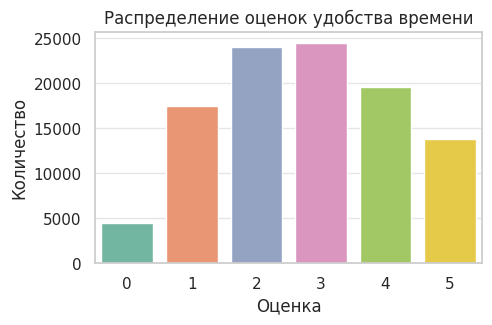

In [27]:
plt.figure(figsize=(5, 3))
sns.countplot(data=df, x='online_booking', palette='Set2')
plt.title('Распределение оценок удобства времени')
plt.xlabel('Оценка')
plt.ylabel('Количество')
sns.set_theme(style="whitegrid")
plt.show()

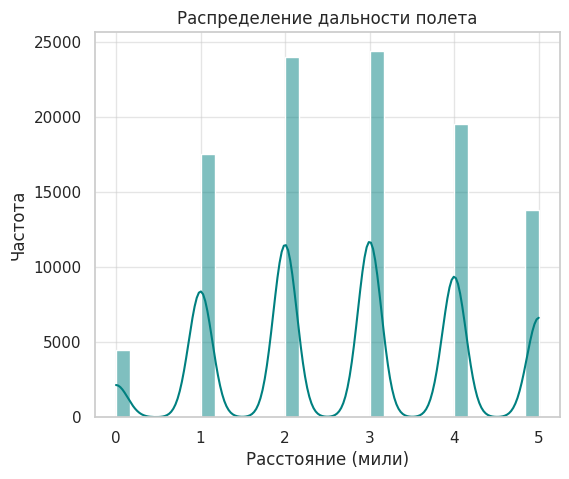

In [28]:
plt.figure(figsize=(6, 5))
sns.histplot(data=df, x='online_booking', bins=30, kde=True, color='teal')
plt.title('Распределение дальности полета')
plt.xlabel('Расстояние (мили)')
plt.ylabel('Частота')
plt.show()


/tmp/ipykernel_257662/1010627817.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='age', palette='Pastel1')


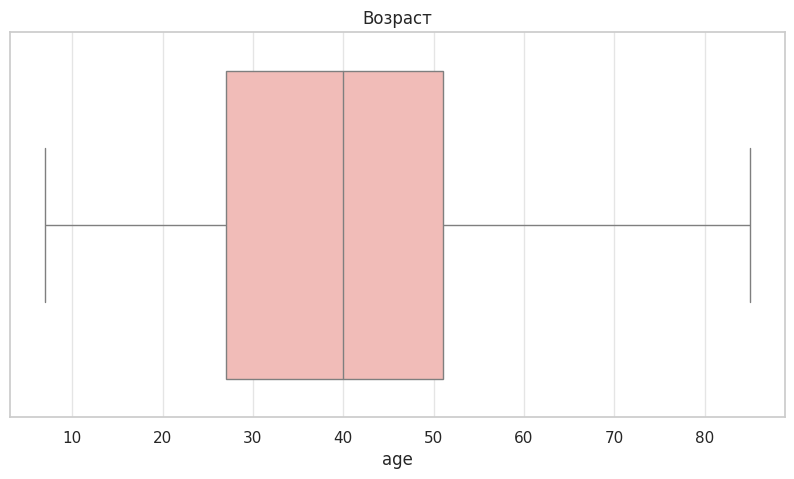

In [29]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='age', palette='Pastel1')
plt.title('Возраст')
plt.show()


In [38]:
print(df.head())

   idx      id  gender      customer_type  age   type_of_travel travel_class  \
0    0   70172    Male     Loyal Customer   13  Personal Travel     Eco Plus   
1    1    5047    Male  disloyal Customer   25  Business travel     Business   
2    2  110028  Female     Loyal Customer   26  Business travel     Business   
3    3   24026  Female     Loyal Customer   25  Business travel     Business   
4    4  119299    Male     Loyal Customer   61  Business travel     Business   

   flight_distance  inflight_wifi  dep_arr_time_convenient  ...  \
0              460              3                        4  ...   
1              235              3                        2  ...   
2             1142              2                        2  ...   
3              562              2                        5  ...   
4              214              3                        3  ...   

   onboard_service  leg_room  baggage_handling  checkin_service  \
0                4         3                 4   

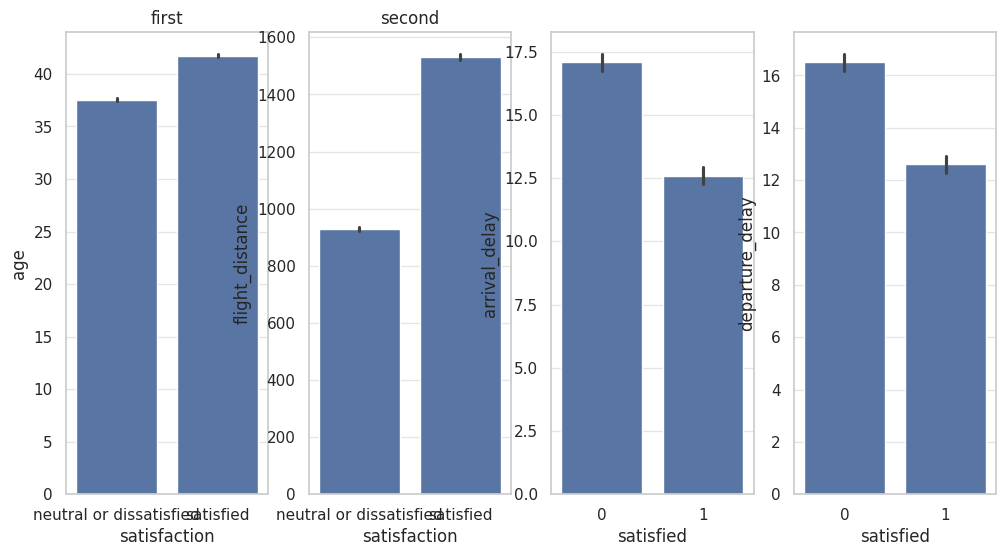

In [50]:
fix, axes = plt.subplots(nrows=1, ncols=4, figsize=(12, 6))
sns.barplot(x = "satisfaction", y="age", data = df, ax=axes[0])
axes[0].set_title("first")
sns.barplot(x = "satisfaction", y="flight_distance", data = df, ax=axes[1])
axes[1].set_title("second")
sns.barplot(x = "satisfied", y="arrival_delay", data = df, ax=axes[2])
sns.barplot(x = "satisfied", y="departure_delay", data = df, ax=axes[3])
plt.show()

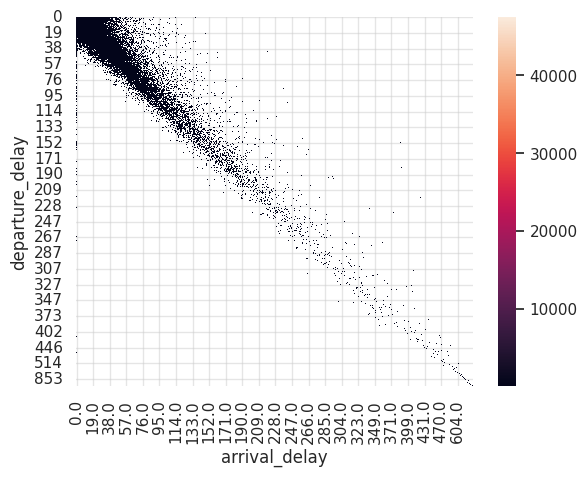

In [59]:
# Создаем сводную таблицу: среднее по задержкам для каждой категории
pivot = df.pivot_table(
    index='departure_delay',
    columns='arrival_delay',
    values='satisfaction',
    aggfunc='count' # Или 'mean', если satisfaction это 0/1
)

sns.heatmap(pivot)
plt.show()

<Axes: xlabel='is_delayed', ylabel='count'>

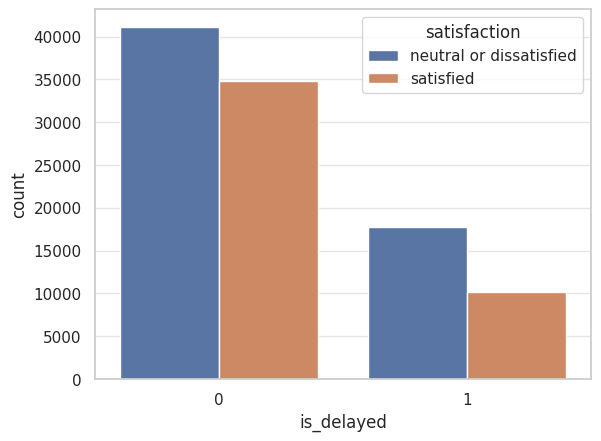

In [60]:
# 1 если задержка была, 0 если нет
df['is_delayed'] = ((df['departure_delay'] > 15) | (df['arrival_delay'] > 15)).astype(int)

# Теперь смотрим, как наличие задержки влияет на satisfaction
sns.countplot(x='is_delayed', hue='satisfaction', data=df)
# Или в процентах:
# pd.crosstab(df['is_delayed'], df['satisfaction'], normalize='index').plot(kind='bar', stacked=True)